# 06 · ¿Está hecho el pueblo para recibir a tanta gente?

Dos preguntas económicas:

1. **Infraestructura:** ¿cuántos hoteles, restaurantes y comercios tiene Magdalena, y cómo se compara con otros municipios de Sonora? (DENUE del INEGI, la única fuente oficial y homogénea).
2. **Derrama:** ¿qué dice la única cifra disponible y cómo se compara con otros santuarios?

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import pandas as pd
import plotly.graph_objects as go

from src import config, tema
from src import procesamiento as proc

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

In [2]:
denue = proc.leer_denue().copy()
denue["sector"] = denue["codigo_act"].map(proc.clasificar_sector)
mag = denue[denue["cve_mun"] == config.CVE_MUN_MAGDALENA]
print(f"Establecimientos en el municipio de Magdalena: {len(mag):,} ({(mag['localidad'].str.strip() == 'Magdalena de Kino').mean():.0%} en la cabecera)")
mag.groupby("sector").agg(establecimientos=("id", "count"), personal_estimado=("personal_estimado", "sum")).sort_values("establecimientos", ascending=False)

Establecimientos en el municipio de Magdalena: 1,475 (99% en la cabecera)


,establecimientos,personal_estimado
sector,,
Otros,757,5437.0
Comercio al por menor,544,2607.0
Alimentos y bebidas,155,685.0
Hospedaje,13,151.5
"Baños, sanitarios y estacionamientos",6,18.0


`personal_estimado` usa el punto medio del rango de personal ocupado que publica el DENUE (por ejemplo, "6 a 10 personas" = 8). Es una aproximación.

## 1. Hospedaje: los 13 hoteles y moteles

In [3]:
hospedaje = mag[mag["sector"] == "Hospedaje"][["nom_estab", "nombre_act", "per_ocu", "fecha_alta"]].sort_values("nom_estab")
hospedaje

,nom_estab,nombre_act,per_ocu,fecha_alta
88451,CASA MONUMENTAL HOTEL,Hoteles sin otros servicios integrados,0 a 5 personas,2013-07
92355,HOTEL ANDARES DE KINO,Hoteles sin otros servicios integrados,6 a 10 personas,2010-07
92445,HOTEL EL TORO,Hoteles con otros servicios integrados,6 a 10 personas,2010-07
92507,HOTEL KINO,Moteles,0 a 5 personas,2010-07
92522,HOTEL LA INDUSTRIA,Departamentos y casas amueblados con servicios...,11 a 30 personas,2019-11
92550,HOTEL LOS CISNES,Hoteles sin otros servicios integrados,6 a 10 personas,2010-07
92559,HOTEL LUCERO,Hoteles con otros servicios integrados,11 a 30 personas,2010-07
92576,HOTEL MI PUEBLO,Hoteles con otros servicios integrados,11 a 30 personas,2020-11
92580,HOTEL MISION SAN JAVIER,Hoteles sin otros servicios integrados,6 a 10 personas,2014-12
92603,HOTEL PEREZ,Hoteles con otros servicios integrados,0 a 5 personas,2010-07


La prensa y las guías turísticas hablaban de 6 a 11 establecimientos; el DENUE registra 13. El DENUE no publica número de cuartos, así que no podemos calcular capacidad en camas.

## 2. ¿Es mucho o poco? Comparación con Sonora

Comparamos por cada mil habitantes contra los municipios de Sonora con más de 15 mil habitantes. Si la oferta de Magdalena estuviera dimensionada para su fiesta, esperaríamos verla cerca de destinos turísticos como Puerto Peñasco o Álamos.

In [4]:
municipios = proc.denue_por_municipio()
municipios = municipios[municipios["pobtot"] > 15000].copy()
for col in ["Hospedaje", "Alimentos y bebidas", "Comercio al por menor"]:
    municipios[f"{col} por mil hab."] = municipios[col] / municipios["pobtot"] * 1000
municipios["rank_hospedaje"] = municipios["Hospedaje por mil hab."].rank(ascending=False).astype(int)
tabla = municipios.sort_values("Hospedaje por mil hab.", ascending=False)[
    ["municipio", "pobtot", "Hospedaje", "Hospedaje por mil hab.", "Alimentos y bebidas por mil hab.", "Comercio al por menor por mil hab.", "rank_hospedaje"]
].round(2)
tabla.head(10)

,municipio,pobtot,Hospedaje,Hospedaje por mil hab.,Alimentos y bebidas por mil hab.,Comercio al por menor por mil hab.,rank_hospedaje
47,Puerto Peñasco,62689,89,1.42,9.54,26.64,1
2,Alamos,24976,22,0.88,3.28,10.69,2
57,Santa Ana,16203,11,0.68,6.23,16.66,3
35,Magdalena,33049,13,0.39,4.69,16.46,4
18,Cananea,39451,15,0.38,4.33,15.49,5
54,San Luis Río Colorado,199021,72,0.36,5.69,16.38,6
70,Benito Juárez,21692,6,0.28,5.81,17.79,7
28,Guaymas,156863,42,0.27,4.41,14.33,8
16,Caborca,89122,22,0.25,5.39,18.12,9
1,Agua Prieta,91929,22,0.24,5.19,16.34,10


In [5]:
fila = tabla[tabla["municipio"] == "Magdalena"].iloc[0]
mediana = tabla["Hospedaje por mil hab."].median()
print(f"Magdalena: {fila['Hospedaje por mil hab.']:.2f} hoteles por mil habitantes, lugar {fila['rank_hospedaje']} de {len(tabla)}")
print(f"Mediana de los municipios comparados: {mediana:.2f}")

Magdalena: 0.39 hoteles por mil habitantes, lugar 4 de 18
Mediana de los municipios comparados: 0.24


Interactiva: outputs/figuras/07_hospedaje_por_mil.html


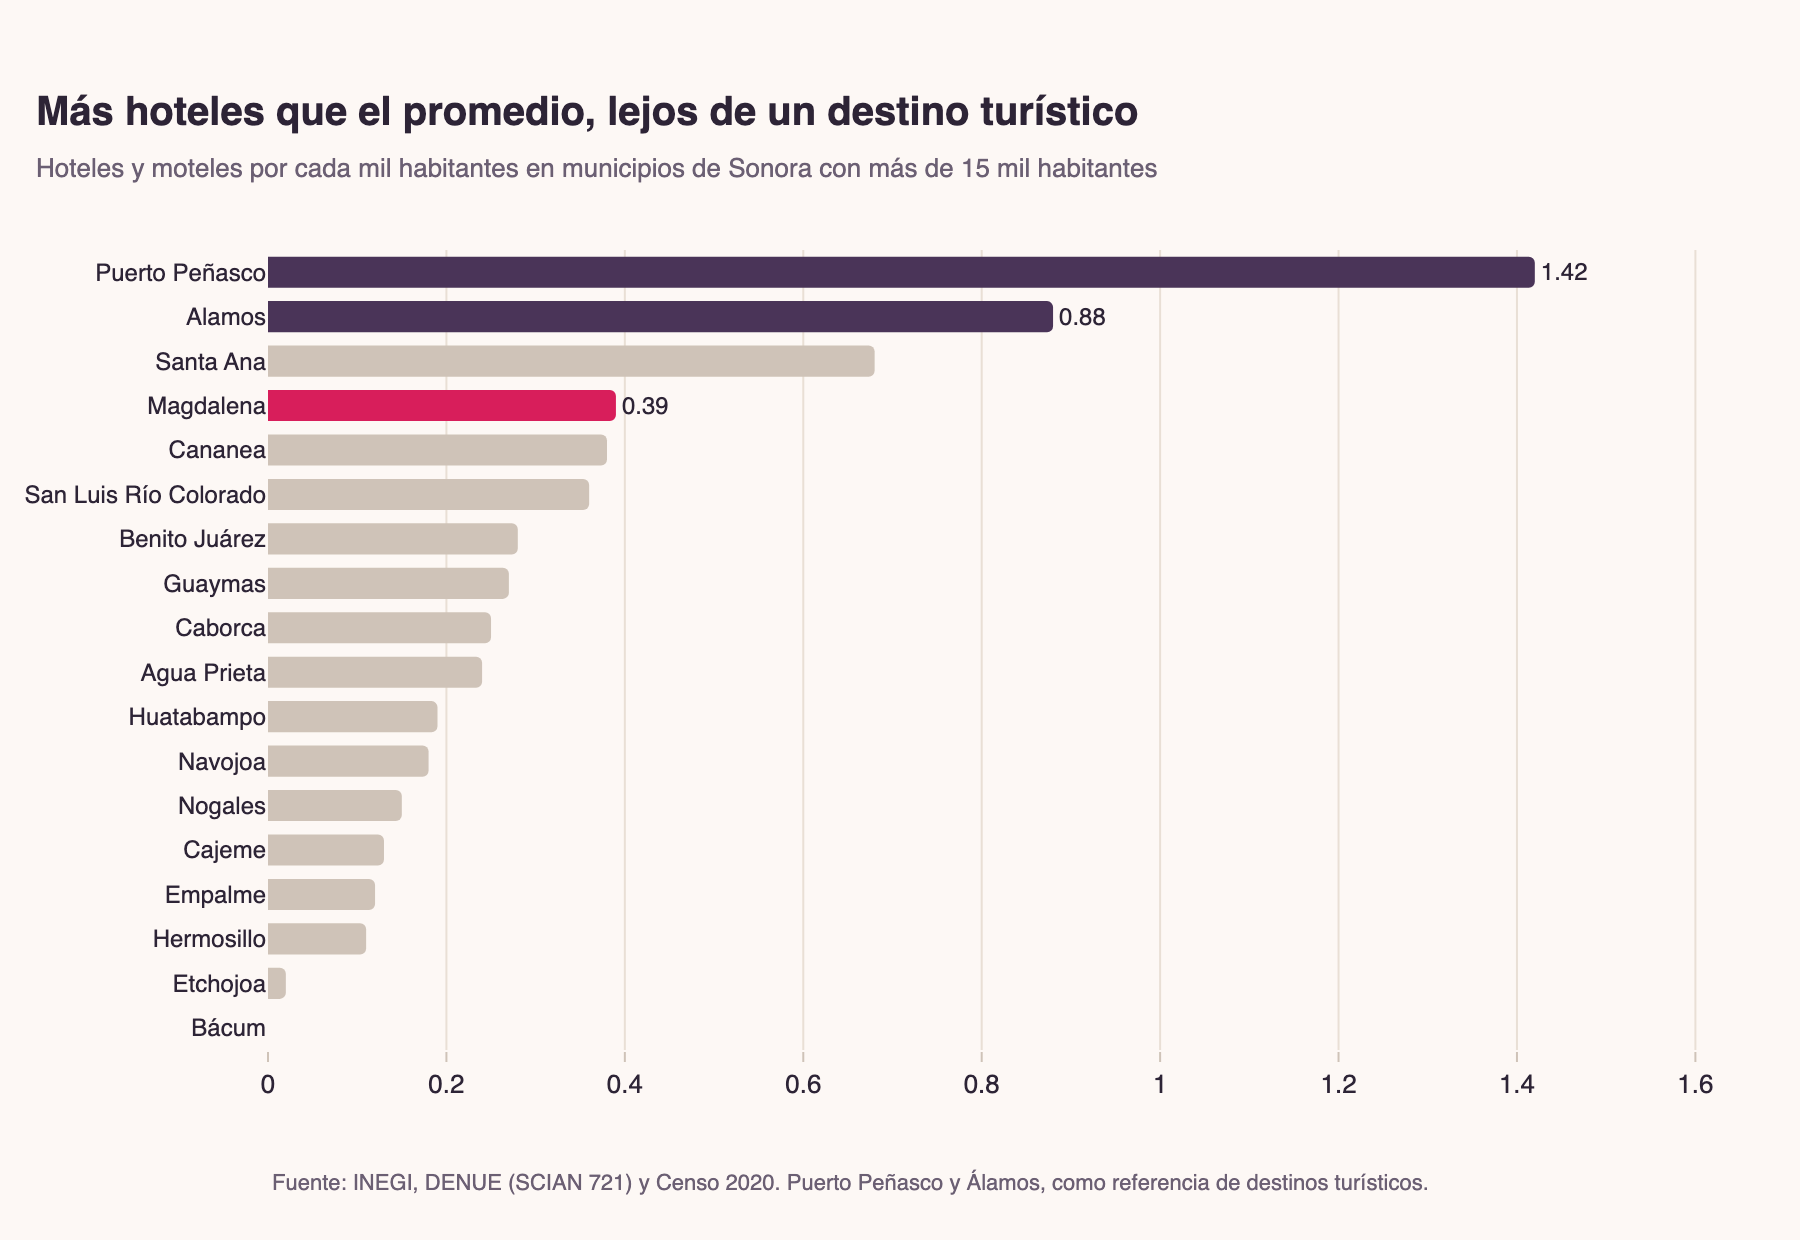

In [6]:
graf = tabla.sort_values("Hospedaje por mil hab.")
destacados = {"Magdalena": tema.PROTAGONISTA, "Puerto Peñasco": tema.CONTORNO, "Alamos": tema.CONTORNO}
fig = go.Figure(go.Bar(
    x=graf["Hospedaje por mil hab."], y=graf["municipio"], orientation="h",
    marker=dict(color=[destacados.get(m, tema.NEUTRO) for m in graf["municipio"]], line=dict(width=0), cornerradius=3),
    text=[f"{v:.2f}" if m in destacados else "" for m, v in zip(graf["municipio"], graf["Hospedaje por mil hab."])],
    textposition="outside", textfont=dict(size=12, color=tema.TEXTO),
    customdata=graf[["Hospedaje", "pobtot"]],
    hovertemplate="<b>%{y}</b><br>%{x:.2f} por mil habitantes<br>%{customdata[0]} establecimientos · %{customdata[1]:,} hab.<extra></extra>",
))
fig.update_layout(
    title=tema.titulo("Más hoteles que el promedio, lejos de un destino turístico",
                      "Hoteles y moteles por cada mil habitantes en municipios de Sonora con más de 15 mil habitantes"),
    xaxis=dict(range=[0, 1.65], showgrid=True, gridcolor=tema.CUADRICULA, title=None),
    yaxis=dict(tickfont=dict(size=12)), height=620, bargap=0.3, showlegend=False,
)
tema.nota_fuente(fig, "Fuente: INEGI, DENUE (SCIAN 721) y Censo 2020. Puerto Peñasco y Álamos, como referencia de destinos turísticos.")
tema.mostrar(fig, "07_hospedaje_por_mil")

**Lectura:** Magdalena está en el cuarto lugar de 18 y por encima de la mediana: tiene más hoteles por habitante que la mayoría de los municipios de su tamaño, quizá justamente por la fiesta y por ser Pueblo Mágico. Pero tiene menos de la mitad que Álamos y menos de un tercio que Puerto Peñasco. Con 13 establecimientos no hay manera de alojar a decenas de miles de visitantes: la fiesta se absorbe con casas de familiares, campamentos y viajes de ida y vuelta.

## 3. La derrama: una sola cifra

La única cifra de derrama localizada es de 2023: "mayor a 60 millones de pesos", según el director de Cultura y Turismo municipal, sin metodología. La ponemos junto a otros santuarios **solo como orden de magnitud**: las metodologías y periodos no son comparables.

In [7]:
comparativos = proc.leer_comparativos()
comparativos["pesos_por_peregrino"] = comparativos["derrama_mdp"] * 1e6 / comparativos["peregrinos"]
comparativos[["destino", "anio", "peregrinos", "derrama_mdp", "pesos_por_peregrino", "quien_mide", "nota"]].round(0)

,destino,anio,peregrinos,derrama_mdp,pesos_por_peregrino,quien_mide,nota
0,Magdalena de Kino,2023.0,60000,60,1000.0,Dirección de Cultura y Turismo municipal (decl...,Única cifra de derrama localizada; sin metodol...
1,Basílica de Guadalupe,2025.0,13200000,21700,1644.0,Proyección citada por El Financiero,Proyección previa al evento
2,San Juan de los Lagos,NaN,700000,4250,6071.0,Secretaría de Turismo de Jalisco (agenda de co...,Peregrinos de la fiesta de la Candelaria y der...
3,México (turismo religioso),NaN,40000000,20000,500.0,Secretaría de Turismo federal,NaN


- En Magdalena, la cifra equivale a unos **1,000 pesos por visitante**; en la Basílica de Guadalupe la proyección de 2025 da unos 1,640.
- La diferencia de fondo no es el monto sino **quién mide**: Guadalupe, San Juan de los Lagos y el turismo religioso nacional tienen una autoridad de turismo que publica la cifra cada año. Magdalena tiene una declaración en 2023 y nada antes ni después.

## Conclusiones

- **13 hoteles y moteles** en el DENUE: 0.39 por mil habitantes, lugar 4 de 18 en Sonora. Está por encima de la mediana (0.24), pero lejos de Álamos (0.88) y Puerto Peñasco (1.42).
- Con 60 mil visitantes, son más de 4,600 por establecimiento.
- La derrama tiene **un solo dato** (60 mdp, 2023), sin método ni continuidad.

In [8]:
tabla.to_csv(config.DIR_PROCESSED / "denue_comparativo_municipios.csv", index=False)
mag.groupby("sector").agg(establecimientos=("id", "count"), personal_estimado=("personal_estimado", "sum")).to_csv(
    config.DIR_PROCESSED / "denue_magdalena_sectores.csv")
comparativos.to_csv(config.DIR_PROCESSED / "comparativos_derrama.csv", index=False)